# Apply Simple Hill Climbing to a Maze Problem

This notebook demonstrates how hill climbing local search behaves applies to the L-Maze problem.

## Setup

In [1]:
# download if missing
import urllib.request
import os

def download(file, base_url):
    if not os.path.exists(file):
        urllib.request.urlretrieve(base_url + file, file)

download("L_maze.txt", 
         "https://raw.githubusercontent.com/mhahsler/Introduction_to_Artificial_Intelligence/refs/heads/master/Local_Search/")
download("maze_helper.py", 
         "https://raw.githubusercontent.com/mhahsler/Introduction_to_Artificial_Intelligence/refs/heads/master/Local_Search/")

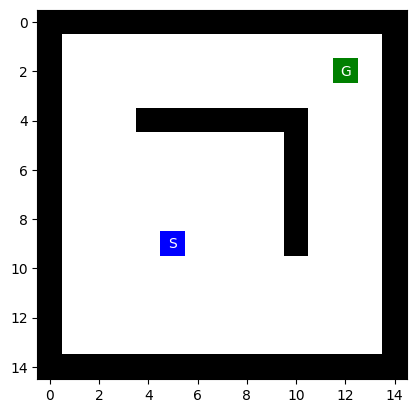

In [2]:
import numpy as np
import maze_helper as mh

f = open("L_maze.txt", "r")

maze_str = f.read()
maze = mh.parse_maze(maze_str)

mh.show_maze(maze)

## Search Helper

We need to define an expand function that will produce the neighbors for local search.

In [3]:
DIR2POS = {
    'N' : (-1, 0),
    'E' : ( 0, 1),
    'S' : ( 1, 0),
    'W' : ( 0,-1)
}

ORDER = None
RANDOMIZATION = None
DIRS = None 

# The order matters if RANDOMIZATION = False
# Note that: DFS works takes elements from the frontier in reverse order!
def set_order(order = "NESW", random = False, verbose = True):
    global RANDOMIZATION, DIR2POS, ORDER, DIRS
    
    RANDOMIZATION = random
    ORDER = [pos for pos in order]
    DIRS = [DIR2POS[dir] for dir in ORDER]
    
    if verbose:
        if RANDOMIZATION:
            print("Directions are checked at every step in random order.")
        else:
            print(f"Directions are checked in the order {ORDER}")
        
set_order("NESW", verbose = True)

Directions are checked in the order ['N', 'E', 'S', 'W']


In [4]:
def expand(maze, pos):
    """find available directions as a list of lists with elements [dir, (pos)]."""
    global RANDOMIZATION, DIRS, ORDER
       
    available = [[dir, pos] for dir, pos in zip(ORDER, np.add(pos, DIRS)) if mh.look(maze, pos) != "X"]
    if RANDOMIZATION: np.random.shuffle(available)
        
    return available

# Hill Climbing

We use Manhattan distance to the goal as the objective function (minimization).

In [5]:
# Manhattan distance h(n)
def manhattan(pos1, pos2):
    """returns the Manhattan distance between two positions"""
    return(np.sum(np.abs(np.subtract(pos1, pos2))))
    
print(manhattan([0,0], [1,1]))

2


In [6]:
def local_search(maze, vis = False, animation = False, verbose = False):
    if animation:
        maze_anim = []
    else:
        maze_anim = None
    
    # Local search starts here
    start_pos = mh.find_pos(maze, "S")
    goal_pos = mh.find_pos(maze, "G")

    current = start_pos
    current_obj = manhattan(current, goal_pos)

    while True:
        # find best neighbor
        neighbors = [n[1] for n in expand(maze, current)]
        obj = [manhattan(n, goal_pos) for n in neighbors]
        best_obj = min(obj)
        best_neighbor = neighbors[obj.index(best_obj)]

        if verbose:
            print("Current state:", current, "with obj", current_obj)
            print("Evaluating neighbors:\t", neighbors)
            print("Obj:\t\t\t", obj)


        # move there if it is an improvement or stop
        if best_obj < current_obj:
            current = best_neighbor
            current_obj = best_obj
            if verbose:
                print("Moving to:", current, "\n")
        else:
            if verbose:
                print("No better state in the neighborhood! Stopping.\n")
            break

        if animation:
            maze2 = maze.copy()
            maze2[current[0], current[1]] = "P"
            maze_anim.append(maze2)


    return { "solution" : current, "path" : None, "reached" : None, "maze_anim" : maze_anim }

## Run the Algorithm

In [7]:
%time result = local_search(maze, animation = True, verbose = True)
result["solution"]

mh.animate_maze(result)

Current state: (np.int64(9), np.int64(5)) with obj 14
Evaluating neighbors:	 [array([8, 5]), array([9, 6]), array([10,  5]), array([9, 4])]
Obj:			 [np.int64(13), np.int64(13), np.int64(15), np.int64(15)]
Moving to: [8 5] 

Current state: [8 5] with obj 13
Evaluating neighbors:	 [array([7, 5]), array([8, 6]), array([9, 5]), array([8, 4])]
Obj:			 [np.int64(12), np.int64(12), np.int64(14), np.int64(14)]
Moving to: [7 5] 

Current state: [7 5] with obj 12
Evaluating neighbors:	 [array([6, 5]), array([7, 6]), array([8, 5]), array([7, 4])]
Obj:			 [np.int64(11), np.int64(11), np.int64(13), np.int64(13)]
Moving to: [6 5] 

Current state: [6 5] with obj 11
Evaluating neighbors:	 [array([5, 5]), array([6, 6]), array([7, 5]), array([6, 4])]
Obj:			 [np.int64(10), np.int64(10), np.int64(12), np.int64(12)]
Moving to: [5 5] 

Current state: [5 5] with obj 10
Evaluating neighbors:	 [array([5, 6]), array([6, 5]), array([5, 4])]
Obj:			 [np.int64(9), np.int64(11), np.int64(11)]
Moving to: [5 6] 

Cu

**Note:** Simple hill climbing is greedy. It gets stuck in local optima!

---
# BÀI 1. TÌM KIẾM CỤC BỘ TRÊN MÊ CUNG – SIMPLE HILL CLIMBING

**Phần thực hành và giải thích bổ sung theo Lab 03.** Giữ nguyên 12 cell của notebook minh họa phía trên. Những cell tiếp theo phân tích hàm `expand`, Manhattan, điểm dừng và thực nghiệm thay đổi `ORDER` / `RANDOMIZATION`.

**Môi trường:** `L_maze.txt`, `maze_helper.py`, NumPy, Matplotlib, Pandas. Các file dữ liệu được đặt cùng thư mục notebook để chạy ngoại tuyến; cell `download()` gốc chỉ tải khi thiếu file.

**Quy ước tọa độ:** `(row, col)` bắt đầu từ 0; `S` là trạng thái bắt đầu, `G` là trạng thái đích, `X` là tường, khoảng trắng là ô đi được. Mỗi hành động `N`, `E`, `S`, `W` thay đổi đúng một tọa độ một đơn vị.

## 1. Quan sát bản đồ, trạng thái và các lân cận

Trong notebook gốc, `DIR2POS` gán `N=(-1,0)`, `E=(0,1)`, `S=(1,0)`, `W=(0,-1)`. Hàm `set_order()` chọn thứ tự xét, `expand(maze, pos)` sinh ra các cặp `[hướng, vị trí kế tiếp]` cho những ô không phải tường. Khi `RANDOMIZATION=True`, danh sách lân cận được xáo trộn bởi `np.random.shuffle()`.

Trong L-maze, các ô biên được bao quanh bởi `X`. Vì vậy, hàm `expand` gốc truy cập trực tiếp vị trí lân cận mà không lỗi vượt biên đối với các trạng thái được khảo sát. Nếu áp dụng cho bản đồ khác không có tường bao, cần bổ sung kiểm tra giới hạn mảng.

In [8]:
import pandas as pd
import matplotlib.pyplot as plt
from collections import deque
from IPython.display import HTML, display

start_b1 = tuple(map(int, mh.find_pos(maze, "S")))
goal_b1 = tuple(map(int, mh.find_pos(maze, "G")))
h_start_b1 = int(manhattan(start_b1, goal_b1))
print(f"Kích thước mê cung: {maze.shape[0]} x {maze.shape[1]}")
print(f"S = {start_b1}; G = {goal_b1}; h(S) = {h_start_b1}")

set_order("NESW", random=False, verbose=False)
initial_neighbors_b1 = []
for direction, position in expand(maze, start_b1):
    target = tuple(map(int, position))
    initial_neighbors_b1.append({
        "Direction": direction,
        "Next state": str(target),
        "h(next)": int(manhattan(target, goal_b1)),
        "Improvement": int(manhattan(target, goal_b1)) < h_start_b1,
    })
display(pd.DataFrame(initial_neighbors_b1))
assert len(initial_neighbors_b1) == 4


Kích thước mê cung: 15 x 15
S = (9, 5); G = (2, 12); h(S) = 14


,Direction,Next state,h(next),Improvement
0,N,"(8, 5)",13,True
1,E,"(9, 6)",13,True
2,S,"(10, 5)",15,False
3,W,"(9, 4)",15,False


## 2. Hàm mục tiêu Manhattan và cách lựa chọn bước

Hàm mục tiêu trong notebook là khoảng cách Manhattan đến đích:

\[
h(n)=|r_n-r_G|+|c_n-c_G|.
\]

Bài toán tối thiểu hóa `h(n)`: bước cải thiện hợp lệ phải có `h(next) < h(current)`; không chấp nhận bước bằng hoặc xấu hơn. Vì hàm mục tiêu chỉ dựa trên tọa độ và không xét tường, một trạng thái có thể có `h(n)>0` nhưng không có hàng xóm nào làm giảm giá trị này.

**Lưu ý về tên thuật toán:** Notebook gốc được đặt tên Simple Hill Climbing, nhưng trong `local_search()` tác giả tính `obj` cho *toàn bộ* lân cận rồi chọn `min(obj)`. Đây là cách chọn lân cận **cải thiện tốt nhất** (best-improvement/steepest-ascent theo chiều tối thiểu hóa), khác với biến thể first-improvement chỉ chọn bước cải thiện đầu tiên. Bản thực hành này giữ nguyên thuật toán của notebook, không âm thầm thay đổi quy tắc chọn bước.

## 3. Kết quả chạy gốc và vị trí dừng

`result["solution"]` của code gốc là **tọa độ nơi thuật toán dừng**, không đồng nghĩa đã tìm đến `G`. Cần kiểm tra trực tiếp `result["solution"] == goal`.

`local_search()` chỉ điền `path=None` và `reached=None`; phần lịch sử từng bước được lưu ở `maze_anim` khi gọi `animation=True`. Vì thế lời nhắn "No solution found" do `maze_helper.animate_maze()` in ra dựa trên `path=None` không thay thế cho việc kiểm tra `solution` và mục tiêu thực sự.

**Vai trò của các tham số:** `maze` là ma trận bản đồ; `animation=True` lưu các frame vào `maze_anim`; `verbose=True` in trạng thái hiện tại, danh sách lân cận và giá trị `obj` để theo dõi từng bước. Tham số `vis` có mặt trong chữ ký hàm nhưng **chưa được sử dụng** trong phần thân hàm gốc; do đó bật `vis=True` không tự tạo hình. Chức năng hiển thị hình/animation được xử lý bởi hàm của `maze_helper` hoặc phần trực quan hóa bổ sung.

In [9]:
set_order("NESW", random=False, verbose=False)
result_b1 = local_search(maze, animation=True, verbose=False)
stop_b1 = tuple(map(int, result_b1["solution"]))

# Mỗi khung trong maze_anim đánh dấu vị trí mới bằng một ký hiệu P.
def trace_from_frames(result, start):
    path = [tuple(map(int, start))]
    for frame in result["maze_anim"] or []:
        marked = np.argwhere(frame == "P")
        assert len(marked) == 1, "Mỗi frame phải có đúng một vị trí P"
        path.append(tuple(map(int, marked[0])))
    return path

trace_b1 = trace_from_frames(result_b1, start_b1)
history_b1 = [int(manhattan(p, goal_b1)) for p in trace_b1]
neighbor_stop_b1 = [
    (direction, tuple(map(int, target)), int(manhattan(target, goal_b1)))
    for direction, target in expand(maze, stop_b1)
]
print("Điểm bắt đầu:", start_b1)
print("Đích G:", goal_b1)
print("Điểm dừng:", stop_b1)
print("Đã đến đích:", stop_b1 == goal_b1)
print("Số bước đã đi:", len(trace_b1) - 1)
print("Dãy h(n):", history_b1)
print("Các lân cận tại điểm dừng:", neighbor_stop_b1)
assert stop_b1 == (5, 9)
assert len(trace_b1)-1 == 8
assert history_b1[0] == 14 and history_b1[-1] == 6
assert all(a > b for a, b in zip(history_b1,history_b1[1:]))
assert all(h >= history_b1[-1] for _,_,h in neighbor_stop_b1)
assert np.array_equal(maze, mh.parse_maze(open("L_maze.txt", encoding="utf-8").read()))


Điểm bắt đầu: (9, 5)
Đích G: (2, 12)
Điểm dừng: (5, 9)
Đã đến đích: False
Số bước đã đi: 8
Dãy h(n): [14, 13, 12, 11, 10, 9, 8, 7, 6]
Các lân cận tại điểm dừng: [('S', (6, 9), 7), ('W', (5, 8), 7)]


### Phân tích điểm dừng

Với dữ liệu gốc, `S=(9,5)` và `G=(2,12)`, nên `h(S)=14`. Sau 8 lần di chuyển, thuật toán dừng ở `(5,9)` với `h=6`. Hai ô có thể đi tới từ điểm dừng là `(6,9)` và `(5,8)`, đều có `h=7`. Do thuật toán chỉ chấp nhận `h(next)<6`, không có bước nào được chọn, dù `(5,9)` khác `G`.

Đây là một **cực tiểu cục bộ** của hàm Manhattan trong tập các lân cận hợp lệ: một đường đi đến G vẫn tồn tại, nhưng cần có lúc đi xa đích hơn theo heuristic để vòng qua tường. Kết quả không chứng minh bản đồ vô nghiệm.

## 4. Trực quan hóa đường đi và sự thay đổi hàm mục tiêu

Hình minh họa dưới đây được dựng trên **bản sao** của dữ liệu mê cung, không ghi các dấu đánh dấu tìm kiếm vào ma trận `maze` gốc. Đường màu xanh thể hiện các vị trí Hill Climbing đã đi qua; điểm dừng được đánh dấu tách biệt với G.

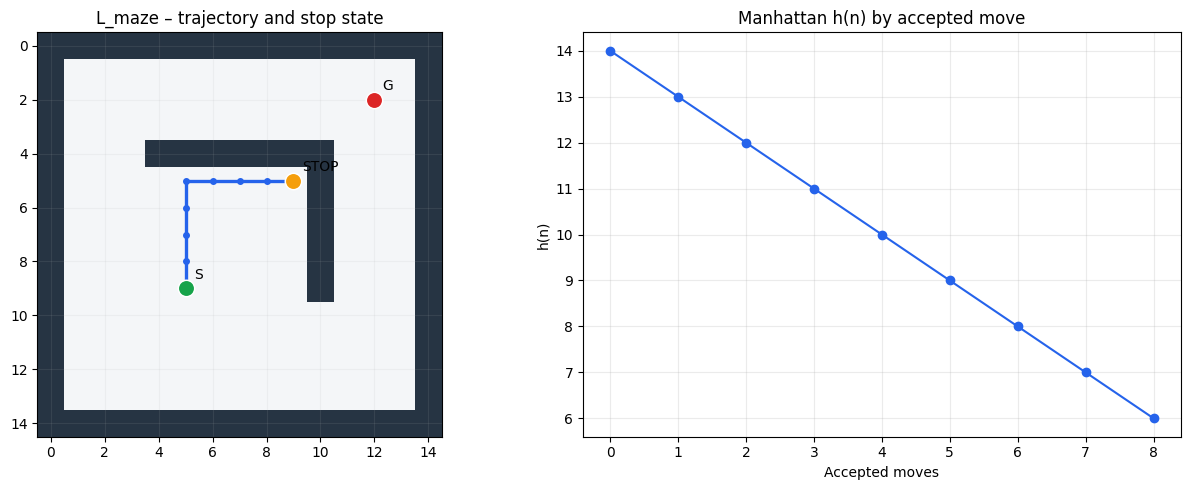

In [10]:
from matplotlib.colors import ListedColormap
fig, axes = plt.subplots(1, 2, figsize=(13, 5), gridspec_kw={"width_ratios": [1.1, 1]})
wall_mask = (maze == "X").astype(int)
axes[0].imshow(wall_mask, cmap=ListedColormap(["#F4F6F8", "#263443"]), vmin=0, vmax=1)
axes[0].plot([p[1] for p in trace_b1], [p[0] for p in trace_b1],
             "-o", color="#2563EB", lw=2.4, ms=4, label="Hill Climbing")
for p, color, label in [(start_b1,"#16A34A","S"), (goal_b1,"#DC2626","G"), (stop_b1,"#F59E0B","STOP")]:
    axes[0].scatter(p[1],p[0], s=140, c=color, edgecolor="white", linewidth=1.1, zorder=4)
    axes[0].annotate(label, (p[1],p[0]), textcoords="offset points", xytext=(6,7), fontsize=10)
axes[0].set_title("L_maze – trajectory and stop state")
axes[0].set_xticks(range(0,maze.shape[1],2)); axes[0].set_yticks(range(0,maze.shape[0],2))
axes[0].grid(alpha=.12)
axes[1].plot(range(len(history_b1)), history_b1, "-o", color="#2563EB")
axes[1].set_title("Manhattan h(n) by accepted move")
axes[1].set_xlabel("Accepted moves")
axes[1].set_ylabel("h(n)")
axes[1].set_xticks(range(len(history_b1))); axes[1].grid(alpha=.25)
fig.tight_layout()
fig.savefig("Lab03_Bai1_HillClimbing_Results.png", dpi=160, bbox_inches="tight")
plt.show()


## 5. Animation của quá trình tìm kiếm

Notebook gốc đã gọi `local_search(maze, animation=True, verbose=True)` và `mh.animate_maze(result)`. Để quan sát rõ cả quá trình lẫn trạng thái dừng, cell bổ sung dưới đây hiển thị một animation độc lập dựa trên `trace_b1`. Khi xem hình, cần lưu ý chấm màu cam ở cuối là **vị trí dừng**, không phải đích G.

In [11]:
from matplotlib.animation import FuncAnimation

fig_anim, ax_anim = plt.subplots(figsize=(5.3,5.3))
ax_anim.imshow((maze == "X").astype(int), cmap=ListedColormap(["#FAFAFA", "#263443"]), vmin=0, vmax=1)
ax_anim.scatter(start_b1[1], start_b1[0], c="#16A34A", s=110, label="S")
ax_anim.scatter(goal_b1[1], goal_b1[0], c="#DC2626", s=110, label="G")
path_artist, = ax_anim.plot([], [], "-o", c="#2563EB", lw=2, ms=4)
point_artist, = ax_anim.plot([], [], "o", c="#F59E0B", ms=12)
ax_anim.set_xlim(-.5, maze.shape[1]-.5); ax_anim.set_ylim(maze.shape[0]-.5,-.5)
ax_anim.legend(loc="upper left"); ax_anim.set_title("Hill Climbing: move 0")

def update_b1(frame):
    nodes = trace_b1[:frame+1]
    path_artist.set_data([p[1] for p in nodes],[p[0] for p in nodes])
    point_artist.set_data([nodes[-1][1]], [nodes[-1][0]])
    ax_anim.set_title(f"Move {frame}/{len(trace_b1)-1} | h={history_b1[frame]}")
    return path_artist, point_artist

anim_b1 = FuncAnimation(fig_anim, update_b1, frames=len(trace_b1), interval=600, repeat=False, blit=False)
plt.close(fig_anim)
display(HTML(anim_b1.to_jshtml()))


## 6. Ảnh hưởng của thứ tự hướng và ngẫu nhiên hóa

Thay đổi `ORDER` sẽ thay đổi thứ tự xét các lân cận khi có nhiều lựa chọn cùng giá trị heuristic. Khi `RANDOMIZATION=True`, `expand()` xáo trộn danh sách lân cận ở mỗi bước. Để các kết quả lặp lại được, cần cố định random seed trước **mỗi lượt** chạy.

Phép khảo sát bên dưới giữ nguyên bản đồ, hàm mục tiêu và quy tắc chọn bước của notebook. Chỉ thay cấu hình hướng và random seed, sau đó thống kê tọa độ dừng, `h(stop)`, số bước và có đạt G hay không.

In [12]:
experiments_b1 = []
orders_b1 = ["NESW", "ENWS", "SENW", "WSEN", "NWSE", "SNWE"]

for order in orders_b1:
    set_order(order, random=False, verbose=False)
    r = local_search(maze, animation=True, verbose=False)
    stop = tuple(map(int, r["solution"]))
    experiments_b1.append({"Mode":"Fixed", "ORDER":order, "seed":"—",
                          "Stop":str(stop), "h(stop)":int(manhattan(stop,goal_b1)),
                          "Steps":len(r["maze_anim"]), "Reached goal":stop==goal_b1})

set_order("NESW", random=True, verbose=False)
for seed in range(10):
    np.random.seed(seed)
    r = local_search(maze, animation=True, verbose=False)
    stop = tuple(map(int, r["solution"]))
    experiments_b1.append({"Mode":"Randomized", "ORDER":"NESW", "seed":seed,
                          "Stop":str(stop), "h(stop)":int(manhattan(stop,goal_b1)),
                          "Steps":len(r["maze_anim"]), "Reached goal":stop==goal_b1})

experiments_df_b1 = pd.DataFrame(experiments_b1)
display(experiments_df_b1)
experiments_df_b1.to_csv("Lab03_Bai1_Experiment_Results.csv", index=False, encoding="utf-8-sig")
print("Tổng lượt chạy:", len(experiments_df_b1))
print("Số lượt tới đích:", int(experiments_df_b1["Reached goal"].sum()))
print("Các vị trí dừng:", sorted(experiments_df_b1["Stop"].unique()))
assert len(experiments_df_b1)==16
assert not experiments_df_b1["Reached goal"].any()
assert experiments_df_b1["Stop"].nunique()==1
set_order("NESW", random=False, verbose=False)  # khôi phục cấu hình mặc định


,Mode,ORDER,seed,Stop,h(stop),Steps,Reached goal
0,Fixed,NESW,—,"(5, 9)",6,8,False
1,Fixed,ENWS,—,"(5, 9)",6,8,False
2,Fixed,SENW,—,"(5, 9)",6,8,False
3,Fixed,WSEN,—,"(5, 9)",6,8,False
4,Fixed,NWSE,—,"(5, 9)",6,8,False
5,Fixed,SNWE,—,"(5, 9)",6,8,False
6,Randomized,NESW,0,"(5, 9)",6,8,False
7,Randomized,NESW,1,"(5, 9)",6,8,False
8,Randomized,NESW,2,"(5, 9)",6,8,False
9,Randomized,NESW,3,"(5, 9)",6,8,False


Tổng lượt chạy: 16
Số lượt tới đích: 0
Các vị trí dừng: ['(5, 9)']


### Nhận xét về thứ tự hướng

Với **6 thứ tự cố định** và **10 seed ngẫu nhiên** được khảo sát, cả 16 lượt chạy đều dừng tại `(5,9)` sau 8 bước với `h(stop)=6`; không lượt nào chạm `G`. Điều này có nghĩa trên L-maze được cung cấp, thay đổi thứ tự xét hoặc xáo trộn hướng **chưa làm thay đổi chất lượng kết quả**. Không nên khẳng định rằng randomization luôn tạo đường đi khác nhau; kết quả phụ thuộc cấu trúc mê cung và các bước cải thiện hợp lệ.

Sự phụ thuộc vào thứ tự vẫn là đặc trưng của Hill Climbing khi có nhiều lân cận cải thiện khác nhau. Những thí nghiệm này chỉ xác nhận rằng các nhánh được chọn ở đây hội tụ về cùng một điểm dừng.

## 7. Kiểm tra phụ: đích có thực sự đi tới được hay không?

Phép kiểm tra BFS dưới đây **không thay thế** thuật toán Hill Climbing của bài tập; chỉ dùng để xác nhận rằng từ S có tồn tại một đường đi hợp lệ đến G dù Hill Climbing bị kẹt bởi hàm mục tiêu. BFS dùng Queue và reached như trong Lab 02, chi phí mỗi bước bằng 1.

In [13]:
def bfs_shortest_steps(maze, start, goal):
    queue = deque([(start, 0)])
    reached = {start}
    for_pos = [(-1,0),(0,1),(1,0),(0,-1)]
    while queue:
        current, depth = queue.popleft()
        if current == goal:
            return depth
        for dr,dc in for_pos:
            nxt=(current[0]+dr,current[1]+dc)
            if (0 <= nxt[0] < maze.shape[0] and 0 <= nxt[1] < maze.shape[1]
                and maze[nxt] != "X" and nxt not in reached):
                reached.add(nxt)
                queue.append((nxt,depth+1))
    return None

shortest_b1 = bfs_shortest_steps(maze, start_b1, goal_b1)
print("BFS – đường đi ngắn nhất từ S đến G:", shortest_b1, "bước")
print("Hill Climbing – điểm dừng:", stop_b1, "| đạt đích:", stop_b1==goal_b1)
assert shortest_b1 == 16


BFS – đường đi ngắn nhất từ S đến G: 16 bước
Hill Climbing – điểm dừng: (5, 9) | đạt đích: False


## 8. Kết luận Bài 1

Bài thực hành đã đọc và hiển thị thành công `L_maze.txt`, xác định các hành động hợp lệ bằng `expand()` và dùng khoảng cách Manhattan để đánh giá các trạng thái lân cận. Với cấu hình ban đầu, thuật toán thực hiện 8 bước, giảm `h` từ 14 xuống 6 nhưng dừng tại `(5,9)`, khác đích `(2,12)`. Không có lân cận hợp lệ nào tại điểm dừng có giá trị `h` nhỏ hơn 6; trong khi kiểm tra độc lập bằng BFS cho thấy vẫn có đường đến đích dài 16 bước. Đây là minh họa rõ ràng cho hiện tượng mắc kẹt tại cực tiểu cục bộ.

Cả 6 thứ tự hướng cố định và 10 seed ngẫu nhiên trong thí nghiệm bổ sung đều cho cùng vị trí dừng. Điều này cho thấy randomization không tự động khắc phục local optimum. Để tăng cơ hội vượt vật cản, có thể nghiên cứu các phương pháp chấp nhận bước xấu tạm thời, thay đổi hàm mục tiêu hoặc các thuật toán khác trong những bài tiếp theo như Random Restart và Simulated Annealing.

**Lưu ý khi đọc code:** Cách chọn `best_obj=min(obj)` trong notebook thực tế xét tất cả lân cận và chọn một lân cận tốt nhất, nên cần phân biệt với phiên bản Simple Hill Climbing chọn bước cải thiện đầu tiên. Tác dụng của randomization trong code chủ yếu là quyết định nút nào được chọn nếu có nhiều lân cận cùng giá trị nhỏ nhất.

Các kết quả đã lưu:
- `Lab03_Bai1_Experiment_Results.csv`: thống kê 16 lượt chạy.
- `Lab03_Bai1_HillClimbing_Results.png`: đường đi và diễn biến `h(n)`.

Mọi phép thử trên bản đồ được thực hiện không thay đổi ma trận `maze` gốc.